# Continuous Optimization in Data Science: Assignment 1

**Group members:**
- Simon Carlén
- Alvin Stallgård

## Q1.1 Gaussian models

**(a)**

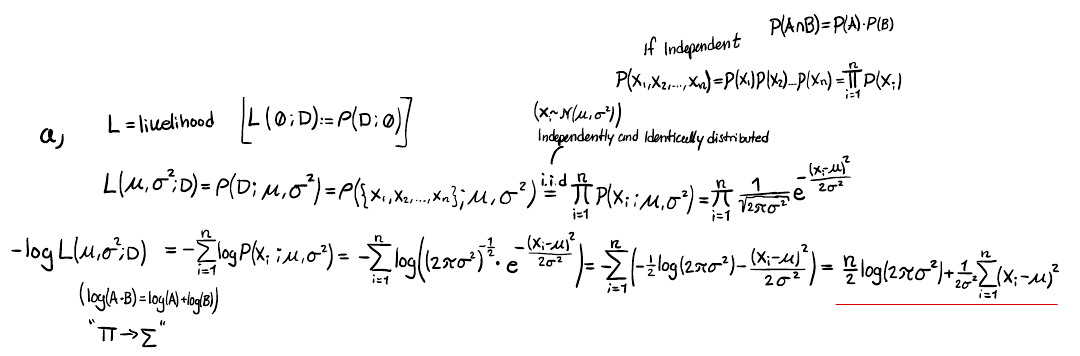

**(b)**

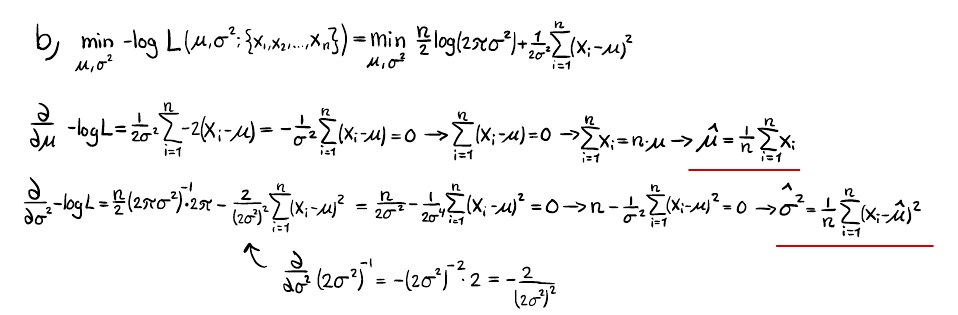

**(c)**

$\mu$ is the mean grade of the students and $\sigma^2$ is the variance of the grades.

Since grades are bounded, $\mu \pm 3\sigma$ should lie within $[0, \text{max}]$. Otherwise the Gaussian assumption breaks down, and the test would be badly calibrated.

## Q1.2 Linear regression

**(a)**

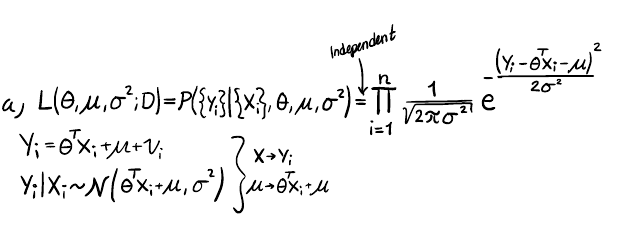

**(b)**

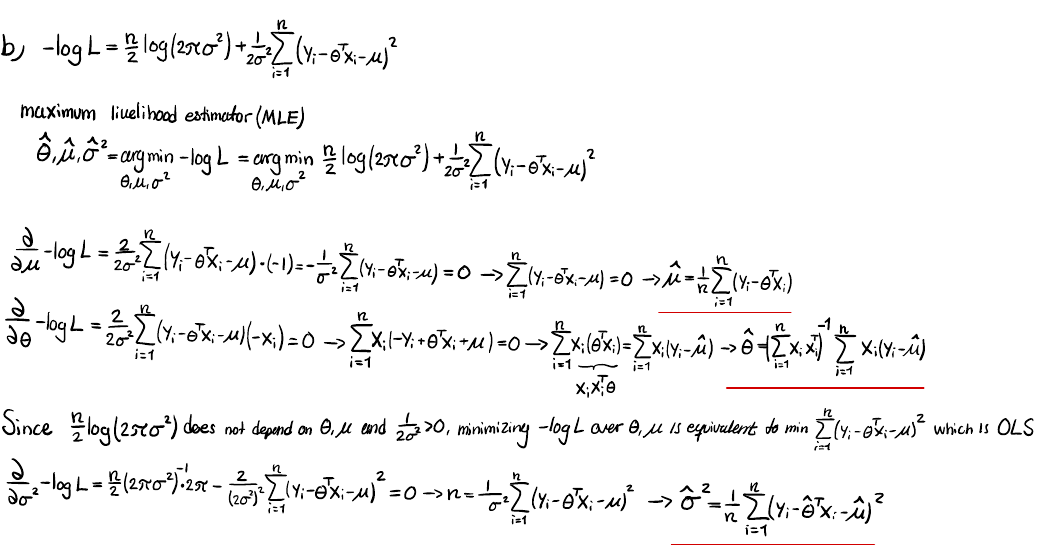

**(c)**

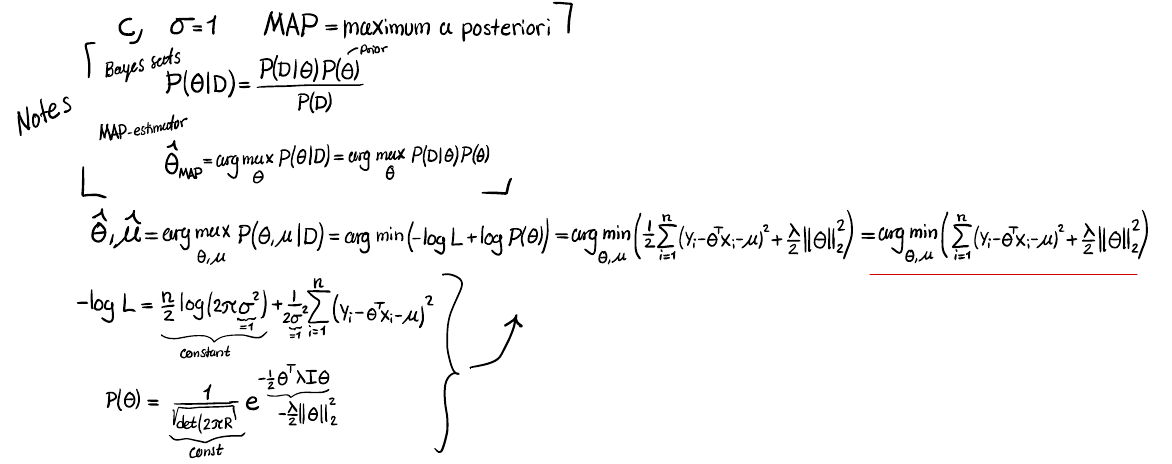

### (d) OLS and ridge regression on the house pricing data

In [1]:
import pandas
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

In [2]:
# Loading the data
data0 = pandas.read_csv('Real estate.csv')
npdata = data0.to_numpy()

# Divide the data to the variables and the label (price)
variables = npdata[:, 1:7]
variables = np.hstack([variables, np.ones((variables.shape[0], 1))])  # ones column -> its weight is the intercept
label = npdata[:, 7]

In [3]:
# alpha=0 gives the maximum likelihood (OLS) solution
model = Ridge(alpha=0, fit_intercept=False).fit(variables, label)
sigma = np.sqrt(np.mean((label - variables @ model.coef_) ** 2))
print(model.coef_)
print(sigma)

[ 5.14622735e+00 -2.69695448e-01 -4.48746113e-03  1.13327691e+00
  2.25472974e+02 -1.24236057e+01 -1.44371000e+04]
8.782466464602782


In [4]:
# Ridge regression with increasing alpha
for alpha in [0, 1, 100, 10000, 1000000]:
    model = Ridge(alpha=alpha, fit_intercept=False).fit(variables, label)
    sigma = np.sqrt(np.mean((label - variables @ model.coef_) ** 2))
    print(alpha, model.coef_, sigma)

0 [ 5.14622735e+00 -2.69695448e-01 -4.48746113e-03  1.13327691e+00
  2.25472974e+02 -1.24236057e+01 -1.44371000e+04] 8.782466464602782
1 [ 6.00702207e-01 -2.53872134e-01 -5.47101395e-03  1.28540141e+00
  7.16096397e+00 -1.10659134e+01 -8.33248071e-02] 9.157291661891492
100 [ 2.81581717e-02 -2.51504875e-01 -5.45875191e-03  1.24199153e+00
  7.39599406e-02 -1.25607257e-01 -9.21298109e-04] 9.205845912061731
10000 [ 2.38173625e-02 -1.98047791e-01 -6.88306876e-03  2.37069188e-01
  1.12527213e-03  1.59438396e-05  1.73409330e-06] 9.543158546079793
1000000 [ 2.27536146e-02 -1.15650945e-02 -7.22627987e-03  2.81023307e-03
  2.90182824e-04  1.35984307e-03  1.12017603e-05] 10.00770558405495


#### 2012 vs 2013

In [5]:
# Divide the data to 2012 and 2013 (X1 is the transaction date) and fit the model on each part
year = np.floor(variables[:, 0])
for y in [2012, 2013]:
    model = Ridge(alpha=0, fit_intercept=False).fit(variables[year == y], label[year == y])
    sigma = np.sqrt(np.mean((label[year == y] - variables[year == y] @ model.coef_) ** 2))
    print(y, model.coef_, sigma)

2012 [-3.58206107e+00 -4.28609585e-01 -4.52214021e-03  1.14845666e+00
  2.11170978e+02 -2.99898081e+01  5.62558940e+03] 6.149596370576956
2013 [ 4.77673635e+00 -1.97957137e-01 -4.33163677e-03  1.12793625e+00
  2.37827393e+02 -3.62703386e-01 -1.54688219e+04] 9.579671015412767


#### Report

**i. What do we learn from θ̂? Which variable is most important?**

Price goes down with house age and distance to the MRT station, and up with the number of convenience stores nearby. The raw coefficients can't be compared directly since the variables have different units, so we multiplied each coefficient by the standard deviation of its variable. Distance to the MRT then has the largest effect (about −5.7, compared to +3.3 for convenience stores and −3.1 for house age), so it's the most important variable in the pricing.

**ii. Is the intercept µ important? What happens if we ignore it?**

Yes. Without the intercept the model is forced through the origin, which doesn't make sense here since no house has date 0 or latitude 0. If we remove it, σ̂ only goes up slightly (8.78 to 8.83), because the date is almost constant and works as an intercept instead. The other coefficients change a lot though, for example longitude goes from −12 to −103.

**iii. What does σ̂ mean? Is it better for it to be small or big?**

σ̂ is the standard deviation of the noise, i.e. how much the price typically differs from the model's prediction. Here it's about 8.8, while the mean price is about 38. A small σ̂ is better since it means the model fits the data well.

**iv. How do θ̂ and σ̂ change with increasing λ?**

As λ increases, the coefficients shrink towards zero. The largest ones shrink fastest, for example the intercept goes from −14437 to almost 0 already at λ = 1. σ̂ increases with λ since the fit gets worse, from 8.78 at λ = 0 to about 10.0 at λ = 10⁶.

**v. Differences between 2012 and 2013? Are per-year models more reliable?**

Yes, σ̂ is lower in 2012 (6.1) than in 2013 (9.6), so the prices in 2013 are harder to predict. Distance to the MRT, convenience stores and house age have about the same effect in both years, while the date, longitude and intercept change a lot. The per-year models fit their own data better, but they're trained on fewer points (126 and 288 instead of 414), so we don't think they're more reliable than one model for the whole dataset.

## Q1.3 Gaussian graphical model

**(a)**

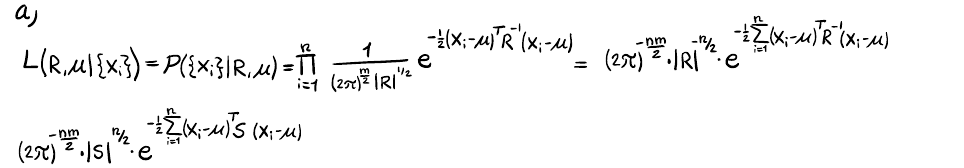

**(b)**

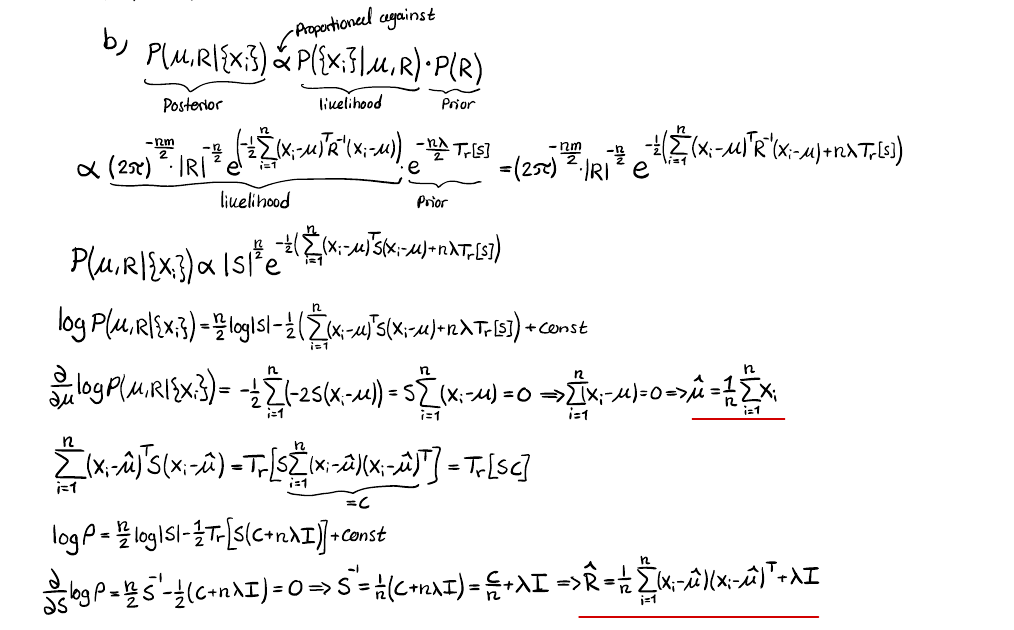

## Q1.4 Gene data

Data: https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/TCGA.BRCA.sampleMap%2FGistic2_CopyNumber_Gistic2_all_data_by_genes.gz

In [6]:
import networkx as nx

# Read the downloaded file (pandas unpacks .gz itself).
# Rows are genes, columns are patients; the first column is the gene name.
data = pandas.read_csv('TCGA.BRCA.sampleMap_Gistic2_CopyNumber_Gistic2_all_data_by_genes.gz', sep='\t')
gene_names = data['Gene Symbol'].to_numpy()
data_clean = data.iloc[:, 1:].to_numpy(dtype=float)  # (genes, patients)
print(data_clean.shape)

(24776, 1080)


In [7]:
lam = 0.1
t = 0.5
n_genes = 100

mean_genes = data_clean.mean(axis=1)
var_genes = data_clean.var(axis=1)

# Select 100 genes (two methods)
first_100_genes = data_clean[:n_genes]
top_var_idx = np.argsort(var_genes)[::-1][:n_genes]
highest_var_genes = data_clean[top_var_idx]

# Calculate the covariance matrix of the selected genes and the precision matrix
covariance_matrix = ((first_100_genes - first_100_genes.mean(axis=1, keepdims=True)) @ (first_100_genes - first_100_genes.mean(axis=1, keepdims=True)).T)/first_100_genes.shape[1] + lam * np.eye(n_genes)
precision_matrix = np.linalg.inv(covariance_matrix)

print(covariance_matrix.shape)

(100, 100)


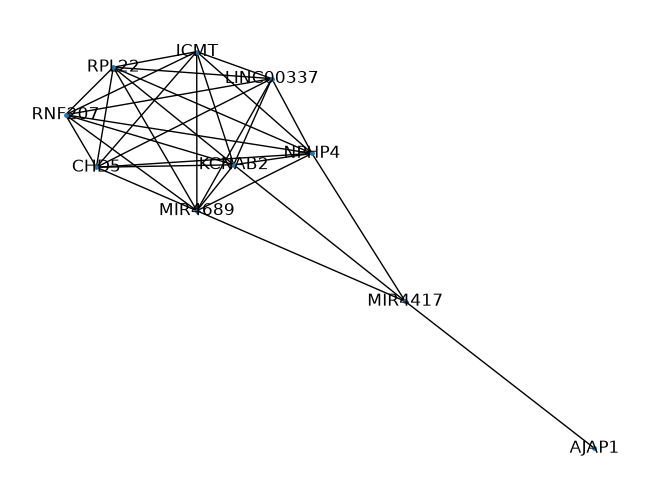

In [8]:
# Add edges to the graph by your precision matrix with graph.add_edge():
# https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.add_edge.html
graph = nx.Graph()
names = gene_names[:n_genes]

for j in range(n_genes):
    for i in range (j + 1, n_genes):
        if abs(precision_matrix[i, j]) > t:
            graph.add_edge(names[i], names[j])

nx.draw(graph, with_labels=True, node_size=6)
plt.show()

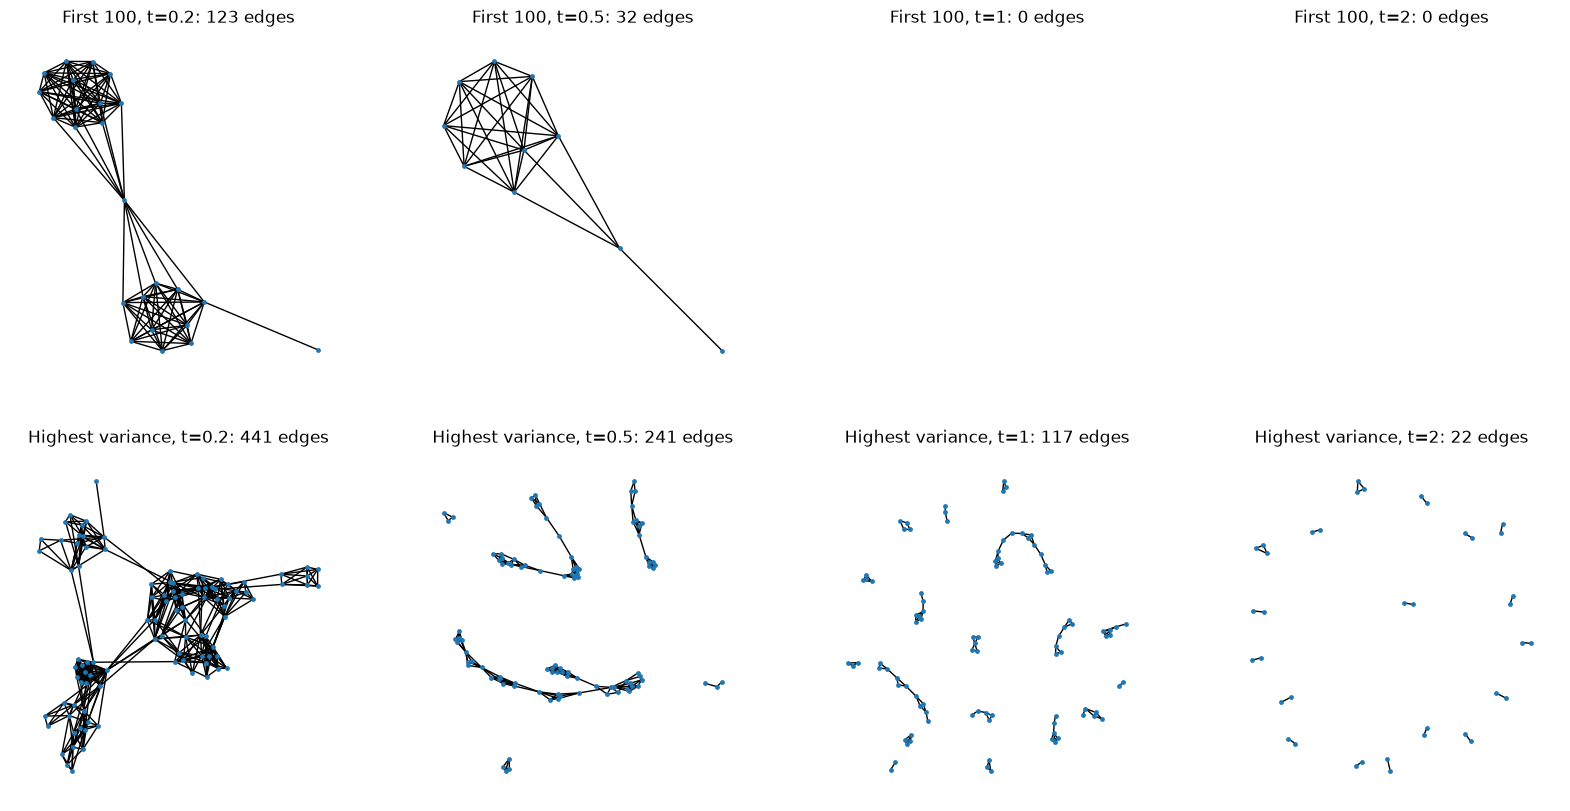

In [9]:
thresholds = [0.2, 0.5, 1, 2]
fig, axes = plt.subplots(2, len(thresholds), figsize=(20, 10))
for row, (title, idx) in enumerate([('First 100', np.arange(n_genes)), ('Highest variance', top_var_idx)]):
    genes = data_clean[idx]
    centered = genes - genes.mean(axis=1, keepdims=True)
    S = np.linalg.inv(centered @ centered.T / genes.shape[1] + lam * np.eye(n_genes))
    for col, thr in enumerate(thresholds):
        g = nx.Graph()
        for j in range(n_genes):
            for i in range(j + 1, n_genes):
                if abs(S[i, j]) > thr:
                    g.add_edge(gene_names[idx][i], gene_names[idx][j])
        nx.draw(g, ax=axes[row, col], with_labels=False, node_size=6, font_size=5)
        axes[row, col].set_title(f'{title}, t={thr}: {g.number_of_edges()} edges')
plt.show()

#### Report

**(a) Effect of λ. Can it be zero? Why not, and when can it?**

λ is added to the diagonal of the covariance, which makes it invertible. A bigger λ makes the values in Ŝ smaller, so we get fewer edges for the same threshold. We can't set λ=0 here since the covariance is singular, a lot of the genes have the same values so the matrix can't be inverted. λ=0 only works if there are more patients than genes and no gene is a linear combination of the others.

**(b) How the threshold is selected.**

We looked at the values in Ŝ and picked t so the graph isn't almost fully connected or empty, just keeping the strongest connections. t depends on λ since λ changes the scale of Ŝ. We used t=0.5.

**(c) Comparing the two gene selections.**

The first 100 genes are next to each other on the same chromosome, so they're almost identical and have low variance. Their graph is just a few clumps and doesn't say much. The top variance genes are more interesting, and the graph has more edges and groups that make more sense.

**(d) Results for several thresholds.**

See the plots above. A small t gives a mess where almost everything is connected, and a bigger t removes edges until only the strongest ones are left. For the first 100 genes everything is gone already around t=1, while the top variance genes still have some edges at t=2.

**(e) What does a big mean value µ̂ imply?**

The data is copy number, so a big mean means the gene has extra copies in many of the patients. That suggests the gene might be involved in the cancer, like MYC which has the highest mean. The mean doesn't affect the graph though, since we subtract it before computing the covariance.

## Q2.1 LP dual

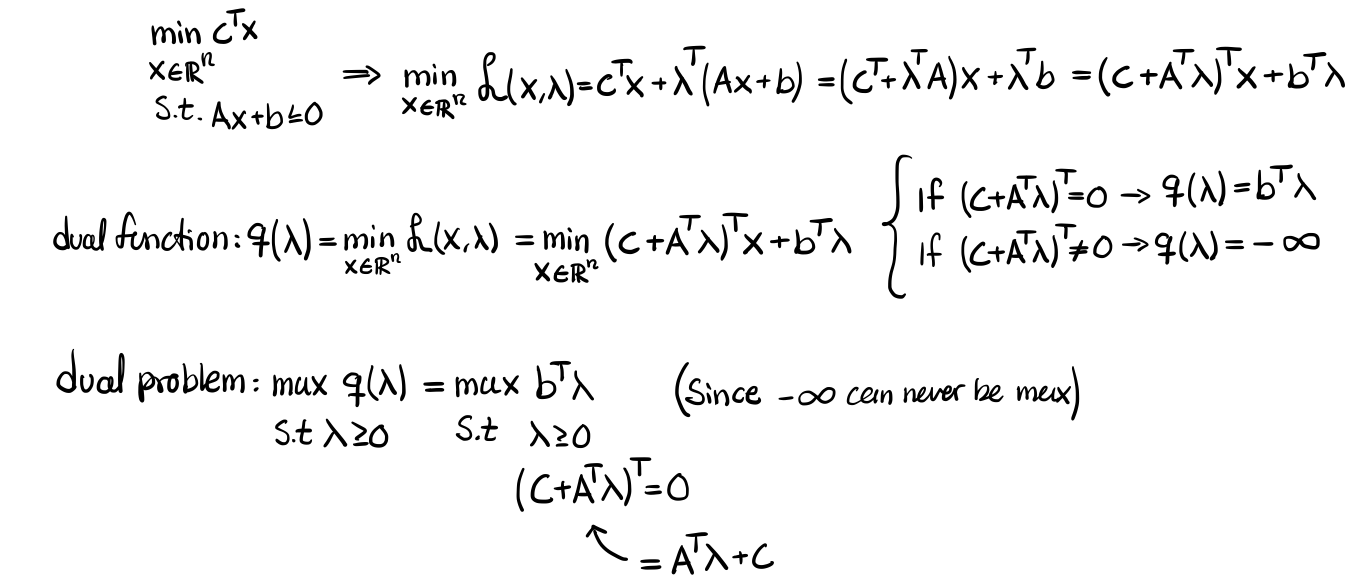